<a href="https://colab.research.google.com/github/drabastomek/datagen/blob/choice_sim/Maria_draft_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [162]:
import cupy as cp
import cudf

# Maria's first attempt on creating the avalability vector with the goal to create a nest logit model

Started 7.2.25

# Customer notes
Availability vector
There should be 200 alternatives + 1 outside good. The outside good is always available. We'll make a slight change to how the other alternatives appear in the data. Their availability can be governed by independent binomial distributions with 50% probability. For each individual, 200 draws from a binomial distribution will correspond to the availability of the 200 alternatives. The key here is we want widely varying choice sets. Some users might be choosing between 3 options whereas others are choosing between 190 options.

In [163]:
# TODO: source these from the YAML file
n = 200

## Tom's notes
We will use the Beta distribution that will give us the probability of selecting or not an alternative. We will then use it to tune the p parameter of the binomial distribution.
### tom's choice to use 2 and 4
(personal preference, this can be adjusted overtime)

With a parameter equal to 2 and the b parameter set to 4 -- we get the below shape for the probabilities

array([[<Axes: title={'center': 'dist'}>]], dtype=object)

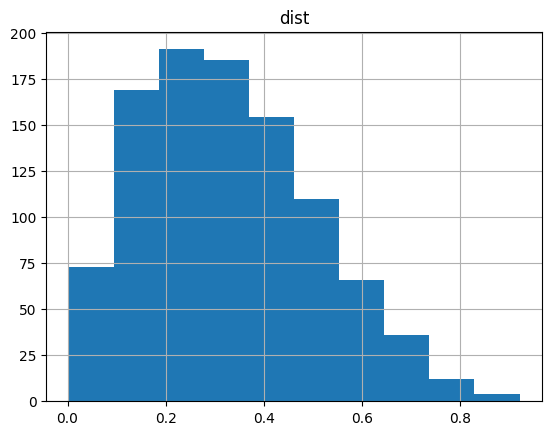

In [164]:
cudf.DataFrame({'dist': cp.random.beta(2,4, size=1000)}).to_pandas().hist()

### Tom's notes:
Using the above defined parameters, we achieve the below distribution of the number of considered alternatives.

(array([[<Axes: title={'center': 'cnts'}>]], dtype=object),
 array([[<Axes: title={'center': 'cnts'}>]], dtype=object))

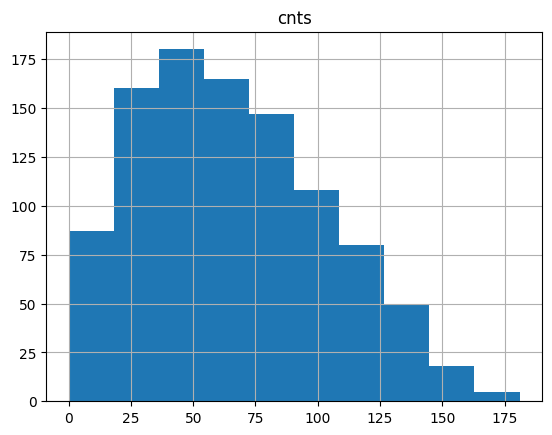

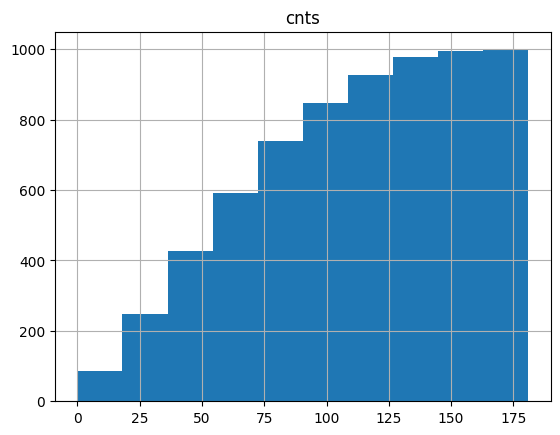

In [165]:
cnts = []
for _ in range(1000):
    # here we're using the beta distribution to determine the probability of being selected as 1
    # this helps with simulating the random number of available alternatives that peaks around 50-75
    # i.e. the median being between 50-75, with a long tail stretching all the way to 200
    avail = cp.random.binomial(1, cp.random.beta(2,4), size=200)
    cnt = sum(avail)
    cnts.append(cnt)

cnts = cudf.DataFrame({'cnts': cnts})
cnts.to_pandas().hist(cumulative=False), cnts.to_pandas().hist(cumulative=True)

## Tom notes
# Data generation (mixed logit)
Each alternative will have 50 features: 45 of which will be homogeneous across alternatives and 5 are heterogeneous and drawn from normal distribution.

$$
\begin{array}{rcl}
V_{1} & = & \beta_{0} * X_{0}^{1} + \ldots + \beta_{45} * X_{45}^{1} + \beta_{46}^{(\mu_{46}, \sigma_{46})} * X_{46}^{1} + \ldots \\
V_{2} & = & \beta_{0} * X_{0}^{2} + \ldots + \beta_{45} * X_{45}^{2} + \beta_{46}^{(\mu_{46}, \sigma_{46})} * X_{46}^{2} + \ldots \\
& \vdots & \\
V_{200} & = & \beta_{0} * X_{0}^{200} + \ldots + \beta_{45} * X_{45}^{200} + \beta_{46}^{(\mu_{46}, \sigma_{46})} * X_{46}^{200} + \ldots \\
\end{array}
$$

The features can be understood as e.g. price, time to wait, time to ride etc.

Also note that the coefficients $\beta_{46 - 50}$ are randomly distributed following normal distribution with their own $\mu$ and $\sigma$ parameters defining the distribution.

Each feature below is standardized to follow normal distribution i.e. $\mu = 0$ and $\sigma = 1$.

In [166]:
alternatives = cp.random.standard_normal(size=(n,50))

## Tom notes
Since we have 45 homogenous coefficients, and 5 coefficients that draw from normal, in total we will have 55 coefficients to estimate: 45 homogeneous + 5 means 𝜇 and 5 standard deviations  𝜎

In [167]:
coefficients = cp.random.standard_normal(size=45)
coefficients_random = cp.random.standard_normal(size=(5,2))
coefficients_random

array([[-0.43795436, -0.67489877],
       [-0.08444188,  1.05121696],
       [-0.46850419, -0.98848306],
       [-0.95223594,  0.38703721],
       [-0.85641633,  0.94906799]])

### Tom notes
Now let's specify the alternative specific constants.

In [168]:
# alternative specific constants, normalize the first one to 0
ASC = cp.random.standard_normal(size=n-1)
ASC = cp.append(cp.array([0.00]), ASC)

### tom notes
The error term is drawn from the Gumbel distribution and is assumed IID and IIA.

In [169]:
# error term
error_term = cp.random.gumbel(0,1, size=200)

### tom notes
Finally, we calculate the utility and determine which alternative is to be chosen based on the list of considered avail alternatives.

In [170]:
utility = cp.append(alternatives[:,:45] * coefficients, alternatives[:,45:] * cp.array([cp.random.normal(*e) for e in coefficients_random]), axis=1)
utility = cp.append(utility, cp.reshape(ASC, (n,1)), axis=1)
utility = cp.append(utility, cp.reshape(error_term, (n,1)), axis=1)

avail = cp.random.binomial(1, cp.random.beta(2,4), size=n)
available_utility = cp.sum(utility, axis=1) * avail

### Tom notes
Now we need to add out 'outside' alternative. To calculate this, we will use the following formula

$$
V_{\mathtt{outside}} = \ln\Bigg(\frac{p}{1-p}\sum_i \exp^{V_{i}}\Bigg) \\
$$
where $p$ is the probability of selecting the $\mathtt{outside}$ alternative.


In [171]:
outside_alternative_prob = 0.9
multiplier = outside_alternative_prob / (1-outside_alternative_prob)

In [172]:
all_utilities = cp.append(available_utility, cp.log(multiplier * cp.sum(cp.exp(available_utility) * avail)))
avail = cp.append(avail, 1) # the outside alternative is always available

In [173]:
all_utilities_exp = cp.exp(all_utilities) * avail
all_utilities_exp_sum = cp.sum(all_utilities_exp)
all_probabilities = all_utilities_exp / all_utilities_exp_sum
res_chart = all_probabilities * 100
res_chart

array([1.60015676e-01, 7.70398620e-05, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 8.95817177e-09,
       5.66640860e-04, 3.06645030e-08, 0.00000000e+00, 1.64430484e-14,
       0.00000000e+00, 3.53322097e-09, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 1.05142538e+00, 3.20106461e-08, 4.37100976e-07,
       1.52953242e-07, 0.00000000e+00, 0.00000000e+00, 6.85684818e-13,
       0.00000000e+00, 0.00000000e+00, 3.67773405e-10, 1.20183406e-02,
       6.51444642e-08, 0.00000000e+00, 2.27876774e-12, 1.01823643e-09,
       1.77513233e-14, 6.45289795e-01, 0.00000000e+00, 8.67746769e-10,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 8.80508074e-04,
       2.30662578e-08, 2.12030053e-04, 0.00000000e+00, 0.00000000e+00,
       1.02377730e-08, 1.91712776e-10, 3.03184494e-13, 0.00000000e+00,
       0.00000000e+00, 2.47828809e-09, 0.00000000e+00, 0.00000000e+00,
       2.26164947e-08, 0.00000000e+00, 0.00000000e+00, 8.07368829e-07,
      

# End of Tom's work

(array([[<Axes: title={'center': 'cnts'}>]], dtype=object),
 array([[<Axes: title={'center': 'cnts'}>]], dtype=object))

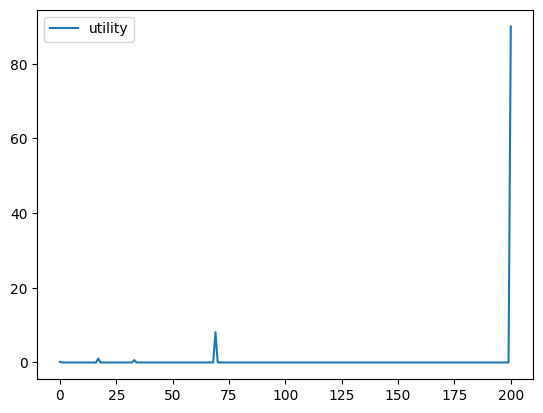

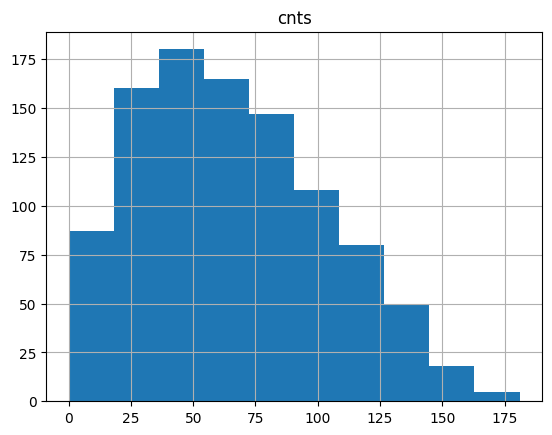

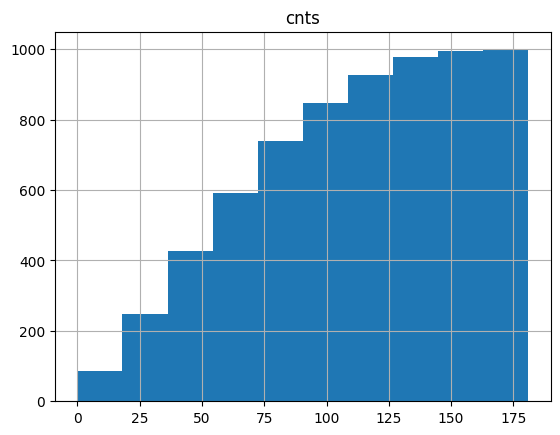

In [174]:
df1 = cudf.DataFrame({'utility': res_chart}).to_pandas().plot()
cnts.to_pandas().hist(cumulative=False), cnts.to_pandas().hist(cumulative=True)

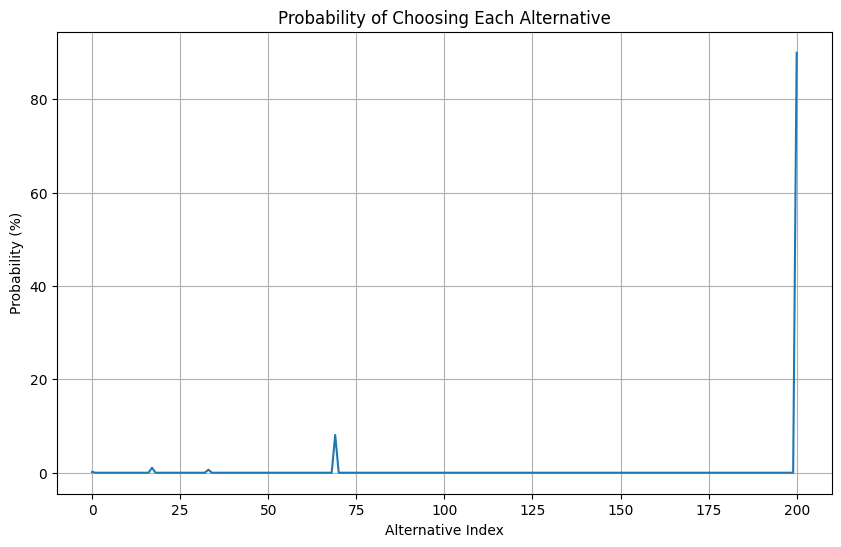

The maximum probability is: 90.00%


In [175]:
import matplotlib.pyplot as plt

# Plot the array
plt.figure(figsize=(10, 6))
plt.plot(res_chart.get())
plt.xlabel('Alternative Index')
plt.ylabel('Probability (%)')
plt.title('Probability of Choosing Each Alternative')
plt.grid(True)
plt.show()

# Find and print the maximum value
max_prob = cp.max(res_chart)
print(f"The maximum probability is: {max_prob.get():.2f}%")

# Data Generation(Nest logit model)


## Breaking down the problem
**Understanding the Nested Logit Structure**

The standard logit model assumes that the choice between any two alternatives is independent of all others (the IIA property). A nested logit model relaxes this assumption by grouping similar alternatives into "nests."

The choice is then modeled as a two-stage process:



1.   **Upper Level:** First, a person chooses a nest.

2.   **Lower Level:** Then, they choose a specific alternative from within that chosen nest.




map each alternative (0-199) to a nest
goal is to have 66 nests( about 3 choices per nest with last nest having 2 alternatives )
parameters will be drawn from predefined dist.(probably beta)

**Define a Nest Structure: Group the 200 alternatives.**


In [176]:
# create the nests and their lambdas

#create nest ids for 67 nests
nest_ids = cp.arange(67)
repeats = [3] * 66 +[2]
# generate random lambda values for each nest (e.g., from a uniform distribution between 0.1 and 1.0)
nest_lambdas_values = cp.random.uniform(0.1, 1.0, size=66)
# map each nest_id to a lambda value
nest_lambdas = {i.item(): v.item() for i, v in zip(nest_ids, nest_lambdas_values)}

alt_to_nest_map = cp.repeat(nest_ids, cp.array(repeats).tolist())

# Update the Utility and Probability Calculation

Final probability is the product of the **nest probability** and the
**conditional alternative**

$P(\text{alternative } i) = P(\text{nest containing } i) \times P(\text{alternative } i \mid \text{nest})$

In [177]:
num_nests = 67
lambda_array = cp.random.beta(8,2, size=num_nests) # using 8,2 bc these are distinct choices


In [178]:
print(f"shape of 'available_utility': {available_utility.shape}")
print(f"shape of 'alt_to_nest_map': {alt_to_nest_map.shape}")
print(f"shape of avail[:200]: {avail[:200].shape}")

shape of 'available_utility': (200,)
shape of 'alt_to_nest_map': (200,)
shape of avail[:200]: (200,)


In [179]:
#new dataframe
nest_df = cudf.DataFrame({
    "nest_utility": available_utility,
    "nest_id": alt_to_nest_map,
    "is_avail": avail[:200]

})
#add lambda columm
nest_df['lambda'] = nest_df['nest_id'].map(nest_lambdas)

**A. Lower-Level Choice: P(alternative |nest)**

This is the probability of choosing an alternative, given that its nest has been selected. The formula is:

$$P(i | n) = \frac{\exp(V_i / \lambda_n)}{\sum_{j \in n} \exp(V_j / \lambda_n)}$$

The denominator, $\sum_{j \in n} \exp(V_j / \lambda_n)$, is used to calculate the Inclusive Value (IV) or "log-sum" of the nest:

$$IV_n = \ln\left(\sum_{j \in n} \exp\left(\frac{V_j}{\lambda_n}\right)\right)$$

The Inclusive Value represents the **expected maximum utility** from that nest.

**B. Upper-Level Choice: P(nest)**
The probability of choosing a nest depends on its inclusive value and its $\lambda$. The "utility" of a nest is $\lambda_n \times IV_n$. The outside good competes at this level. The formula for the probability of choosing a nest is:

$$P(n) = \frac{\exp(\lambda_n IV_n)}{\sum_{m \in N} \exp(\lambda_m IV_m) + \exp(V_{outside})}$$

Where $N$ is the set of all nests.

In [180]:
 #sum of the exponentiated utilities of all available inside goods
sum_V = cp.sum(cp.exp(available_utility) * avail[:n]) # 'avail' is the 200th element
v_outside = (outside_alternative_prob / (1 - outside_alternative_prob)) * sum_V #get 200 element

Inclusive Value Formula: $IV_n = \ln\left(\sum_{j \in n} \exp\left(\frac{V_j}{\lambda_n}\right)\right)$

Nest Utility Formula: $Nest\ Utility_n = \lambda_n \times IV_n$

## Clean up the data and create a new dataframe

**Find IV**

In [203]:
#Calculate Nest Choice Probabilities P(n)
nest_df['nest_utility'].mask(nest_df['is_avail'] == 0, cp.NINF) # remove unavailable alternatives


0      17.916257
1      10.277553
2           -inf
3           -inf
4           -inf
         ...    
195    15.504755
196         -inf
197     7.425997
198         -inf
199     2.169507
Name: nest_utility, Length: 200, dtype: float64

In [204]:
#calculate scaled utility of each nest
nest_df['scaled_utility']=nest_df['nest_utility'] / nest_df['lambda']

In [205]:
#exp scaled utility of each nest

unmasked_exp_scaled_utility = nest_df['scaled_utility'].fillna(cp.NINF)
nest_df['exp_scaled_utility'] = cp.exp(unmasked_exp_scaled_utility)


In [184]:
#group by nest id
nest_sums = nest_df.groupby('nest_id')['exp_scaled_utility'].sum()

#find Inclusive Value

inclusive_values = cp.log(nest_sums)

print("Inclusive Value(IV) for each nest:")
print(inclusive_values)

Inclusive Value(IV) for each nest:
[ 5.46485338e+01  1.09861229e+00  6.93147324e-01  2.95517984e+00
  6.93147181e-01  4.69809079e+00  6.53856048e+00  5.08946373e+01
  1.02446433e+01  2.16339667e+01  8.74152732e+00  3.97619788e+01
  2.07204096e+01  2.09763540e+01  6.97451000e+00  5.46793446e-05
  1.29765442e+01  2.37322891e+01  0.00000000e+00  8.92627429e-05
  2.58615515e+01  1.09861229e+00  4.62977011e+00  1.38493623e+01
  1.19095968e+01  7.28955588e-01  6.95009705e-01  1.62886822e+00
  3.58365579e+00  5.62861830e-05  2.58649600e+00  7.13187626e+01
  7.13267531e-01  9.43097115e-01  8.20520718e+00  2.48065779e+01
            -inf  1.06773790e+00  8.87595132e+00  1.97582933e+00
  1.90205028e+01  6.93494008e-01  3.63652241e+01  2.98404911e+01
 -1.51532126e+00  1.12693398e+01  6.93147181e-01  1.09861229e+00
  2.44649189e+01  9.59484809e+00  2.73542931e+01  1.75249288e+00
  6.93175328e-01  3.89472826e+01  1.09861229e+00  2.25465975e+01
  4.99363676e+01  2.42974081e+01  1.86949900e+01  9.413

In [185]:
#add IV column

# Convert inclusive_values CuPy array to cuDF Series with nest_id as index
inclusive_values_series = cudf.Series(inclusive_values, index=nest_sums.index)
nest_df['inclusive_value'] = nest_df['nest_id'].map(inclusive_values_series)
iv_col = nest_df['inclusive_value']


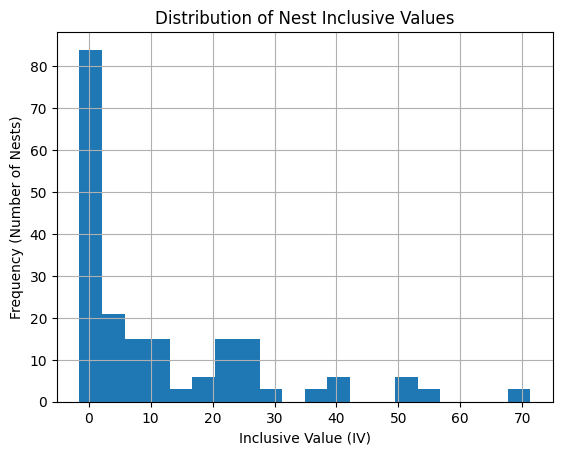

In [186]:
#visualize IV(histogram)

iv_col[cp.isfinite(iv_col)].to_pandas().hist(bins=20)
plt.xlabel('Inclusive Value (IV)')
plt.ylabel('Frequency (Number of Nests)')
plt.title('Distribution of Nest Inclusive Values')
plt.show()

In [202]:
#sorted Data table
iv_df = cudf.DataFrame({'inclusive_value': inclusive_values})

# Sort the nests from most attractive to least attractive
sorted_iv = iv_df.sort_values(by='inclusive_value', ascending=False)

print("Top 10 Most Attractive Nests by IV:")
print(sorted_iv.head(10))

print("\nBottom 10 Least Attractive Nests by IV:")
print(sorted_iv.tail(10))

Top 10 Most Attractive Nests by IV:
    inclusive_value
31        71.318763
0         54.648534
7         50.894637
56        49.936368
11        39.761979
53        38.947283
42        36.365224
43        29.840491
50        27.354293
20        25.861551

Bottom 10 Least Attractive Nests by IV:
    inclusive_value
4      6.931472e-01
46     6.931472e-01
63     6.931472e-01
19     8.926274e-05
29     5.628618e-05
15     5.467934e-05
59     9.413797e-07
18     0.000000e+00
44    -1.515321e+00
36             -inf


## Calculate the probablities - this is where the wheels fell off


In [198]:
total_denominator = cp.sum(unmasked_exp_scaled_utility) + v_outside
nest_probabilities = unmasked_exp_scaled_utility.values / total_denominator
print("Probabilities for the first 5 nests:")
print(nest_probabilities[:5])



Probabilities for the first 5 nests:
[-0. -0.  0. -0. -0.]


calculate conditional probablities

In [199]:
nest_df['nest_sums'] = nest_df['nest_id'].map(nest_sums)

# The conditional probability is the exponentiated scaled utility divided by the sum for its nest.
nest_df['conditional_prob'] = nest_df['exp_scaled_utility'] / nest_df['nest_sums']

calculate final probabilities

In [201]:
nest_df['final_prob'] = nest_df['conditional_prob'] * nest_df['nest_prob']
print(nest_df['final_prob'].head())

0   -0.0
1   -0.0
2   -0.0
3   -0.0
4   -0.0
Name: final_prob, dtype: float64
